# Wang et al. 2019 — Glioblastoma (GBM)
## 03 · Signatures & Gate 2

**Gate 2** asks whether the embryonic module pattern appears. In the **non-branching** case that means
a *shared* Gast/pSom gradient with **Crest as an inverse, terminal readout** (§1) — a real GO outcome,
distinct from a NO-GO where no pattern is present. Geography is read from the graph-smoothed scores;
the deliverable panels show the **raw per-cell scores** on the manifold (04_test rule: smoothing aids
analysis but the deliverable must show raw). Module→role is read off the *scores*, not subtype names.

In [1]:
import os, sys, glob, io, contextlib, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
%matplotlib inline
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.stats import spearmanr
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # 'Wang2019_Brain-3'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Brain'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
# raw input folder = dataset minus the attempt suffix and with the Data_ prefix
raw = 'Data_' + name.split('-')[0]                      # 'Data_Wang2019_Brain'
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_feat= os.path.join(pth_data, 'features', 'biomart')
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 9634 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 100/104 genes present


### Gate 2 — module geography and the developmental gradient

In [4]:
rr = {}
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    rr[(a,b)] = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {rr[(a,b)]:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
rho = {}
print('\ngradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho[sname], _ = spearmanr(t, adata.obs[sname]); print(f'  {sname}: rho = {rho[sname]:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
crest_pt = tn[hi.values].mean()
print(f'\nNeural-crest-high decile mean pseudotime = {crest_pt:.2f} (terminal if ~1)')
print('global module means (raw):', {m: round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})

r_gp = rr[('Gast_sm','pSom_sm')]
crest_opposes = rr[('Crest_sm','Gast_sm')] < 0 and rr[('Crest_sm','pSom_sm')] < 0
# Gate 2 GO: an embryonic module pattern is present. Non-branching form = shared Gast/pSom gradient
# (r>0) + Crest an inverse, terminal readout. Branching form = Gast/pSom compete into two arms.
pattern_present = (r_gp > 0 and crest_opposes and crest_pt > 0.6)
branching = r_gp < 0
gate2 = 'GO' if pattern_present or branching else 'NO-GO'
subcase = 'branching' if branching else 'non-branching'
# flag rule: Crest enriches the Gast arm (inversion). No arms here -> no flag.
crest_flag = ''
gate3 = 'testable (branching)' if branching else 'NA'
print(f'\nGast/pSom co-vary (r={r_gp:+.2f}) + Crest inverse terminal (decile pt {crest_pt:.2f}); no competing arms -> no flag.')
print(f'GATE 2: embryonic module pattern present -> {gate2} ({subcase}){crest_flag}')
print(f'GATE 3: {gate3}')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.16
  Crest_sm vs Gast_sm: r = -0.49
  Crest_sm vs pSom_sm: r = -0.87

gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.055
  pSom_sm: rho = -0.610
  Crest_sm: rho = +0.482

Neural-crest-high decile mean pseudotime = 0.85 (terminal if ~1)
global module means (raw): {'Gast': -0.002, 'pSom': 0.008, 'Crest': -0.007}

Gast/pSom co-vary (r=+0.16) + Crest inverse terminal (decile pt 0.85); no competing arms -> no flag.
GATE 2: embryonic module pattern present -> GO (non-branching)
GATE 3: NA


### Module maps — raw per-cell scores, house linear layout

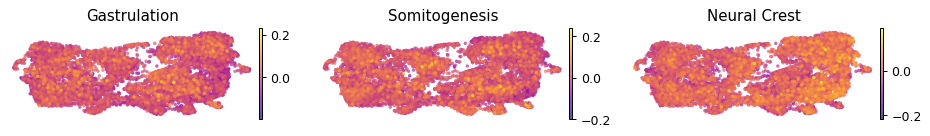

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax, (m, title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
fig.tight_layout(); plt.show()

### Deliverables — per-module signature PDFs + external colorbars (raw scores)

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


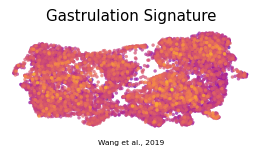

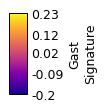

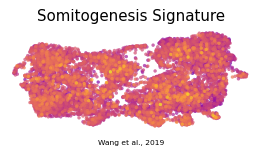

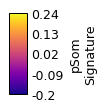

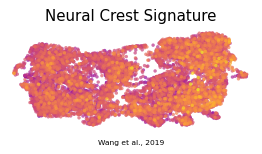

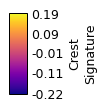

In [6]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
    ax.text(.5, -.12, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show()
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [7]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (9634, 26409)
